# Affect Dynamics for Big Five Personality Prediction from Text

**Research question.** Do affective signals (sentiment and discrete emotions), and in particular how they *change across a text*, improve Big Five personality prediction beyond contextual transformer representations?

**Pipeline overview**

1. **Data:** the full Essays dataset (Pennebaker & King, 1999), about 2,467 stream-of-consciousness essays with binary labels for all five traits (O, C, E, A, N).
2. **Affect dynamics features:** every essay is split into 64-word segments. A sentiment model and an emotion model score each segment, and we summarise the resulting trajectories (mean, variability, extremes, trend, volatility, first-half vs second-half shift).
3. **Text representation:** chunked MPNet sentence embeddings covering the whole essay.
4. **Models:** majority class, TF-IDF + LR, affect-only LR, embedding-only LR, early fusion, the **proposed late (stacked) fusion**, ablations, fine-tuned RoBERTa, and a zero-shot LLM.
5. **Evaluation:** 10-fold cross-validation repeated 3 times (shared folds across all models), accuracy, macro-F1 and ROC-AUC, plus the corrected resampled t-test (Nadeau & Bengio, 2003) with Holm correction.
6. **Analysis:** affect–trait correlations (BH-FDR), model coefficients, emotion trajectories, and error analysis.

**How to run (Kaggle):** Settings → Accelerator **GPU T4 x1** (or P100), Internet **On**, then *Save Version → Save & Run All*. Expected runtime is about 5–6 hours with everything enabled. Set `run_finetune` / `run_llm` to `False` in the config cell for a fast (~1 hour) run.

Every result, table and figure is written to `outputs/`, and a zip archive is created at the end.

In [1]:
# ================================================================
# 0. Install (Kaggle/Colab already ship torch, transformers and scikit-learn)
# ================================================================
!pip install -q datasets statsmodels

In [2]:
# ================================================================
# 1. Imports, configuration and reproducibility
# ================================================================
import os, re, json, math, time, random, pickle, platform, warnings, gc, shutil, inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.patches
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from joblib import Parallel, delayed
from tqdm.auto import tqdm

import torch
from torch.utils.data import DataLoader, TensorDataset
import transformers
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          AutoModelForCausalLM, get_linear_schedule_with_warmup)
from datasets import load_dataset
from packaging import version

import sklearn
from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"          # also silences joblib worker processes
transformers.logging.set_verbosity_error()

CFG = {
    "seed": 42,
    "n_folds": 10,
    "n_repeats": 3,
    "n_jobs": -1,
    "out_dir": "outputs",
    # --- affect dynamics ---
    "segment_words": 64,
    "affect_batch_size": 64,
    "sentiment_model": "cardiffnlp/twitter-roberta-base-sentiment-latest",
    "emotion_model": "j-hartmann/emotion-english-distilroberta-base",
    # --- document embeddings ---
    "embedding_model": "sentence-transformers/all-mpnet-base-v2",
    "embedding_max_len": 384,
    "embedding_stride": 64,
    "embedding_batch_size": 8,
    # --- fine-tuned transformer baseline ---
    "run_finetune": True,
    "finetune_model": "roberta-base",
    "ft_max_len": 512,
    "ft_max_chunks": 4,
    "ft_max_epochs": 6,              # upper bound; early stopping on an inner validation split
    "ft_patience": 2,
    "ft_val_frac": 0.1,              # fraction of each training fold held out for early stopping + threshold
    "ft_lr": 1e-5,
    "ft_batch_size": 8,
    "ft_grad_accum": 2,              # effective batch size = 16
    "ft_warmup": 0.1,
    "ft_weight_decay": 0.01,
    # --- zero-shot LLM baseline ---
    "run_llm": True,
    "llm_model": "Qwen/Qwen2.5-3B-Instruct",
    "llm_max_essay_tokens": 1200,
    "llm_max_essays": None,          # None = all essays; an int scores only the first n
}

TRAITS = ["O", "C", "E", "A", "N"]
TRAIT_NAMES = {"O": "Openness", "C": "Conscientiousness", "E": "Extraversion",
               "A": "Agreeableness", "N": "Neuroticism"}
SEED = CFG["seed"]

OUT = Path(CFG["out_dir"]); CACHE = OUT / "cache"; FIG = OUT / "figures"; TAB = OUT / "tables"
for d in (OUT, CACHE, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

env = {
    "python": platform.python_version(), "torch": torch.__version__,
    "transformers": transformers.__version__, "sklearn": sklearn.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
json.dump({"config": CFG, "environment": env}, open(OUT / "run_config.json", "w"), indent=2)
print(json.dumps(env, indent=2))
if DEVICE.type != "cuda":
    print("WARNING: no GPU detected. Feature extraction, fine-tuning and the LLM will be very slow.")


def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def dtype_kwargs(dtype):
    """`torch_dtype` was renamed to `dtype` in recent transformers releases."""
    key = "dtype" if version.parse(transformers.__version__) >= version.parse("4.56.0") else "torch_dtype"
    return {key: dtype}

{
  "python": "3.13.15",
  "torch": "2.11.0+cu128",
  "transformers": "5.16.1",
  "sklearn": "1.6.1",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "device": "cuda",
  "gpu": "Tesla T4"
}


In [3]:
# ================================================================
# 2. Load the Essays dataset (all splits merged, cross-validation is used instead)
# ================================================================
def clean_text(t):
    t = str(t).replace("\x00", " ")
    return re.sub(r"\s+", " ", t).strip()


def to_binary(v):
    if isinstance(v, str):
        s = v.strip().lower()
        if s in ("y", "yes", "1", "1.0", "true", "high"):
            return 1
        if s in ("n", "no", "0", "0.0", "false", "low"):
            return 0
        raise ValueError(f"Unexpected label value: {v!r}")
    return int(round(float(v)))


ESSAYS_URL = "https://raw.githubusercontent.com/SenticNet/personality-detection/master/essays.csv"
ORIG_COLS = {"TEXT": "text", "cOPN": "O", "cCON": "C", "cEXT": "E", "cAGR": "A", "cNEU": "N"}


def normalise_columns(d):
    d = d.rename(columns=ORIG_COLS)
    missing = [c for c in ["text"] + TRAITS if c not in d.columns]
    if missing:
        raise ValueError(f"missing columns {missing}; found {list(d.columns)}")
    return d[["text"] + TRAITS].copy()


def load_essays():
    """Original Essays corpus (Pennebaker & King, 1999) as distributed by Majumder et al. (2017).
    Tries 3 sources in order: GitHub mirror -> Hugging Face -> any matching CSV in /kaggle/input."""
    errors = []
    try:
        d = normalise_columns(pd.read_csv(ESSAYS_URL, encoding="latin-1"))
        print("Loaded Essays from GitHub (SenticNet/personality-detection)")
        return d
    except Exception as e:
        errors.append(f"GitHub: {e}")
    try:
        raw = load_dataset("jingjietan/essays-big5")
        d = normalise_columns(pd.concat([raw[s].to_pandas() for s in raw.keys()], ignore_index=True))
        print("Loaded Essays from Hugging Face (jingjietan/essays-big5)")
        return d
    except Exception as e:
        errors.append(f"Hugging Face: {type(e).__name__}: {str(e)[:200]}")
    for p in sorted(Path("/kaggle/input").rglob("*.csv")) if Path("/kaggle/input").exists() else []:
        try:
            d = normalise_columns(pd.read_csv(p, encoding="latin-1"))
            print(f"Loaded Essays from Kaggle input: {p}")
            return d
        except Exception as e:
            errors.append(f"{p}: {e}")
    raise RuntimeError("Could not load the Essays dataset. Make sure Internet is ON "
                       "(Settings -> Turn on internet), or attach essays.csv via 'Add Input'.\n" + "\n".join(errors))


df = load_essays()
df["text"] = df["text"].map(clean_text)
n_before = len(df)
df = df[df["text"].str.len() > 0].drop_duplicates("text").reset_index(drop=True)
for t in TRAITS:
    df[t] = df[t].map(to_binary)
assert set(np.unique(df[TRAITS].values)) <= {0, 1}, "Labels must be binary"

texts = df["text"].tolist()
Y = df[TRAITS].values.astype(int)
N = len(df)
print(f"Essays: {N} (removed {n_before - N} empty/duplicate rows)")

# ---- descriptive statistics (Table: dataset) ----
df["n_words"] = df["text"].str.split().str.len()
desc = pd.DataFrame({
    "Trait": [TRAIT_NAMES[t] for t in TRAITS],
    "High (%)": [100 * df[t].mean() for t in TRAITS],
    "Low (%)": [100 * (1 - df[t].mean()) for t in TRAITS],
}).round(1)
print(f"Words per essay: mean={df.n_words.mean():.0f}, sd={df.n_words.std():.0f}, "
      f"min={df.n_words.min()}, max={df.n_words.max()}")
print(desc.to_string(index=False))
desc.to_csv(TAB / "dataset_label_balance.csv", index=False)
trait_corr = df[TRAITS].corr().round(3)
trait_corr.to_csv(TAB / "trait_label_correlations.csv")
print("\nInter-trait label correlations (phi):\n", trait_corr)

Loaded Essays from GitHub (SenticNet/personality-detection)
Essays: 2467 (removed 0 empty/duplicate rows)
Words per essay: mean=652, sd=254, min=33, max=2500
            Trait  High (%)  Low (%)
         Openness      51.5     48.5
Conscientiousness      50.8     49.2
     Extraversion      51.7     48.3
    Agreeableness      53.1     46.9
      Neuroticism      50.0     50.0

Inter-trait label correlations (phi):
        O      C      E      A      N
O  1.000 -0.027  0.079  0.018 -0.047
C -0.027  1.000  0.136  0.134 -0.148
E  0.079  0.136  1.000  0.124 -0.160
A  0.018  0.134  0.124  1.000 -0.190
N -0.047 -0.148 -0.160 -0.190  1.000


In [4]:
# ================================================================
# 3. Affect dynamics features
#    Segment-level sentiment (3 classes) and emotion (7 classes) -> trajectory statistics
# ================================================================
def segment_text(text, n_words):
    words = text.split()
    if not words:
        return [text]
    return [" ".join(words[i:i + n_words]) for i in range(0, len(words), n_words)]


def model_inputs(model, enc):
    """Keep only the tensors the model's forward() accepts (e.g. drops token_type_ids for MPNet)."""
    accepted = set(inspect.signature(model.forward).parameters)
    return {k: v for k, v in enc.items() if k in accepted}


@torch.no_grad()
def classify_segments(model_name, segments, batch_size, max_len=128):
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEVICE).eval()
    if DEVICE.type == "cuda":
        model.half()
    labels = [model.config.id2label[i].lower() for i in range(model.config.num_labels)]
    probs = np.zeros((len(segments), len(labels)), dtype=np.float32)
    order = np.argsort([len(s) for s in segments])          # length bucketing = faster batches
    for start in tqdm(range(0, len(order), batch_size), desc=model_name.split("/")[-1]):
        idx = order[start:start + batch_size]
        enc = tok([segments[i] for i in idx], truncation=True, max_length=max_len,
                  padding=True, return_tensors="pt")
        enc = {k: v.to(DEVICE) for k, v in model_inputs(model, enc).items()}
        probs[idx] = torch.softmax(model(**enc).logits.float(), dim=-1).cpu().numpy()
    del model; free_gpu()
    return probs, labels


STAT_NAMES = ["mean", "std", "min", "max", "slope", "volatility", "half_shift"]


def trajectory_stats(seq):
    """seq: (T segments, D affect dimensions) -> 7*D statistics."""
    T = len(seq)
    mean, std, mn, mx = seq.mean(0), seq.std(0), seq.min(0), seq.max(0)
    if T > 1:
        pos = np.linspace(0, 1, T)
        slope = np.polyfit(pos, seq, 1)[0]
        vol = np.abs(np.diff(seq, axis=0)).mean(0)
        h = T // 2
        half = seq[h:].mean(0) - seq[:h].mean(0)
    else:
        slope = vol = half = np.zeros(seq.shape[1])
    return np.concatenate([mean, std, mn, mx, slope, vol, half])


affect_cache = CACHE / "affect_features.npz"
if affect_cache.exists():
    z = np.load(affect_cache)
    A_all, A_names, series_names = z["A"], list(z["names"]), list(z["series_names"])
    series = pickle.load(open(CACHE / "affect_series.pkl", "rb"))
    print("Loaded cached affect features:", A_all.shape)
else:
    seg_lists = [segment_text(t, CFG["segment_words"]) for t in texts]
    lengths = np.array([len(s) for s in seg_lists])
    flat = [s for segs in seg_lists for s in segs]
    print(f"Segments: {len(flat)} (mean {lengths.mean():.1f} per essay)")

    sent_p, sent_labels = classify_segments(CFG["sentiment_model"], flat, CFG["affect_batch_size"])
    emo_p, emo_labels = classify_segments(CFG["emotion_model"], flat, CFG["affect_batch_size"])
    print("Sentiment labels:", sent_labels, "| Emotion labels:", emo_labels)

    valence = sent_p[:, sent_labels.index("positive")] - sent_p[:, sent_labels.index("negative")]
    S = np.column_stack([sent_p, emo_p, valence]).astype(np.float32)
    series_names = [f"sent_{l}" for l in sent_labels] + [f"emo_{l}" for l in emo_labels] + ["valence"]
    series = np.split(S, np.cumsum(lengths)[:-1])

    sent_cols = list(range(len(sent_labels)))
    emo_cols = list(range(len(sent_labels), len(sent_labels) + len(emo_labels)))
    rows = []
    for seq in series:
        dom = seq[:, sent_cols].argmax(1)
        shift_rate = float((dom[1:] != dom[:-1]).mean()) if len(seq) > 1 else 0.0
        e = np.clip(seq[:, emo_cols], 1e-8, 1)
        entropy = float((-(e * np.log(e)).sum(1)).mean())
        rows.append(np.concatenate([trajectory_stats(seq), [shift_rate, entropy]]))
    A_all = np.vstack(rows).astype(np.float32)
    A_names = [f"{s}__{st}" for st in STAT_NAMES for s in series_names] + ["sent__shift_rate", "emo__entropy"]
    pickle.dump(series, open(CACHE / "affect_series.pkl", "wb"))
    np.savez(affect_cache, A=A_all, names=np.array(A_names), series_names=np.array(series_names))

A_names = list(A_names)
idx_of = {n: i for i, n in enumerate(A_names)}
cols_static = [i for i, n in enumerate(A_names) if n.endswith("__mean")]
cols_dynamic = list(range(len(A_names)))
cols_sentiment = [i for i, n in enumerate(A_names) if n.startswith(("sent", "valence"))]
cols_emotion = [i for i, n in enumerate(A_names) if n.startswith("emo")]
A_static, A_dynamic = A_all[:, cols_static], A_all[:, cols_dynamic]
A_sent, A_emo = A_all[:, cols_sentiment], A_all[:, cols_emotion]
print(f"Affect features: static={A_static.shape[1]}, dynamic={A_dynamic.shape[1]}, "
      f"sentiment-only={A_sent.shape[1]}, emotion-only={A_emo.shape[1]}")
pd.DataFrame(A_all, columns=A_names).assign(**{t: Y[:, k] for k, t in enumerate(TRAITS)}) \
  .to_csv(OUT / "affect_features.csv", index=False)

Segments: 26353 (mean 10.7 per essay)


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

... (14 outputs left out)

emotion-english-distilroberta-base:   0%|          | 0/412 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  329MB            

model.safetensors: downloading bytes:           |  0.00B            

Sentiment labels: ['negative', 'neutral', 'positive'] | Emotion labels: ['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']
Affect features: static=11, dynamic=79, sentiment-only=29, emotion-only=50


In [5]:
# ================================================================
# 4. Whole-document embeddings (overlapping chunks, mean-pooled, token-weighted)
# ================================================================
@torch.no_grad()
def embed_documents(model_name, docs, max_len, stride, batch_size, sub_batch=32):
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(DEVICE).eval()
    if DEVICE.type == "cuda":
        model.half()
    out = np.zeros((len(docs), model.config.hidden_size), dtype=np.float32)
    for i0 in tqdm(range(0, len(docs), batch_size), desc="embeddings"):
        batch = docs[i0:i0 + batch_size]
        enc = tok(batch, truncation=True, max_length=max_len, stride=stride,
                  return_overflowing_tokens=True, padding=True, return_tensors="pt")
        mapping = enc.pop("overflow_to_sample_mapping").numpy()
        enc = model_inputs(model, enc)
        pooled = []
        for j in range(0, len(mapping), sub_batch):
            part = {k: v[j:j + sub_batch].to(DEVICE) for k, v in enc.items()}
            h = model(**part).last_hidden_state.float()
            m = part["attention_mask"].unsqueeze(-1).float()
            pooled.append(((h * m).sum(1) / m.sum(1).clamp(min=1)).cpu())
        H = torch.cat(pooled).numpy()
        w = enc["attention_mask"].sum(1).numpy().astype(float)
        for d in range(len(batch)):
            sel = mapping == d
            out[i0 + d] = np.average(H[sel], axis=0, weights=w[sel])
    del model; free_gpu()
    return out / np.linalg.norm(out, axis=1, keepdims=True).clip(min=1e-8)


emb_cache = CACHE / "embeddings.npy"
if emb_cache.exists():
    E = np.load(emb_cache)
else:
    E = embed_documents(CFG["embedding_model"], texts, CFG["embedding_max_len"],
                        CFG["embedding_stride"], CFG["embedding_batch_size"])
    np.save(emb_cache, E)
print("Embeddings:", E.shape)

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

embeddings:   0%|          | 0/309 [00:00<?, ?it/s]

Embeddings: (2467, 768)


In [7]:
# ================================================================
# 5. Evaluation framework: shared repeated 10-fold splits, metrics, result store
# ================================================================
SPLITS = list(RepeatedKFold(n_splits=CFG["n_folds"], n_repeats=CFG["n_repeats"],
                            random_state=SEED).split(np.zeros(N)))
SPLIT_META = [(r, f) for r in range(CFG["n_repeats"]) for f in range(CFG["n_folds"])]
RESULTS, OOF, EXTRA = [], {}, {}


def compute_metrics(y, prob, pred=None):
    pred = (prob >= 0.5).astype(int) if pred is None else pred
    try:
        auc = roc_auc_score(y, prob)
    except ValueError:
        auc = np.nan
    return {"acc": accuracy_score(y, pred), "f1": f1_score(y, pred, average="macro"), "auc": auc}


def record(name, probs_by_split, preds_by_split=None):
    """probs_by_split: {split_index: (n_test, 5) probabilities}."""
    global RESULTS
    RESULTS = [r for r in RESULTS if r["model"] != name]
    oof = np.full((CFG["n_repeats"], N, len(TRAITS)), np.nan)
    for si, probs in probs_by_split.items():
        r, f = SPLIT_META[si]
        te = SPLITS[si][1]
        oof[r, te] = probs
        for k, t in enumerate(TRAITS):
            valid = ~np.isnan(probs[:, k])
            if valid.sum() < 2:
                continue
            pred = None if preds_by_split is None else preds_by_split[si][valid, k]
            m = compute_metrics(Y[te, k][valid], probs[valid, k], pred)
            RESULTS.append({"model": name, "trait": t, "repeat": r, "fold": f, **m})
    OOF[name] = oof
    res = pd.DataFrame([x for x in RESULTS if x["model"] == name])
    print(f"{name:<45s} acc={res.acc.mean():.4f}  F1={res.f1.mean():.4f}  AUC={res.auc.mean():.4f}")


def record_from_full(name, P, repeats=(0,), Pred=None):
    """For predictions defined for every essay (e.g. zero-shot or out-of-fold), scored on the shared folds."""
    sis = [i for i, (r, _) in enumerate(SPLIT_META) if r in repeats]
    record(name, {si: P[SPLITS[si][1]] for si in sis},
           None if Pred is None else {si: Pred[SPLITS[si][1]] for si in sis})


def make_lr(inner_cv=5, Cs=(1e-3, 1e-2, 1e-1, 1.0)):
    return make_pipeline(
        StandardScaler(),
        LogisticRegressionCV(Cs=list(Cs), cv=StratifiedKFold(inner_cv, shuffle=True, random_state=SEED),
                             scoring="neg_log_loss", max_iter=5000))


def make_tfidf_lr():
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30000, sublinear_tf=True),
        LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                             scoring="neg_log_loss", solver="liblinear", max_iter=5000))


def make_majority():
    return DummyClassifier(strategy="most_frequent")


def _fit_split(si, X, factory):
    tr, te = SPLITS[si]
    is_text = isinstance(X, list)
    Xtr = [X[i] for i in tr] if is_text else X[tr]
    Xte = [X[i] for i in te] if is_text else X[te]
    probs = np.zeros((len(te), len(TRAITS)))
    for k in range(len(TRAITS)):
        est = factory().fit(Xtr, Y[tr, k])
        probs[:, k] = est.predict_proba(Xte)[:, 1]
    return si, probs


def run_model(name, X, factory, repeats=None):
    sis = [i for i, (r, _) in enumerate(SPLIT_META) if repeats is None or r in repeats]
    outs = Parallel(n_jobs=CFG["n_jobs"])(delayed(_fit_split)(si, X, factory) for si in sis)
    record(name, dict(outs))


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _late_fusion_split(si, X_emb, affect_sets):
    """Stacked fusion: inner-CV out-of-fold probabilities of an embedding LR and an affect LR
    are combined by a logistic meta-learner trained only on the outer training fold."""
    tr, te = SPLITS[si]
    out = {name: np.zeros((len(te), len(TRAITS))) for name in affect_sets}
    weights = {name: np.zeros((len(TRAITS), 2)) for name in affect_sets}
    for k in range(len(TRAITS)):
        y_tr = Y[tr, k]
        inner = StratifiedKFold(5, shuffle=True, random_state=SEED + si)
        base_e = make_lr(inner_cv=3)
        oof_e = cross_val_predict(base_e, X_emb[tr], y_tr, cv=inner, method="predict_proba")[:, 1]
        te_e = clone(base_e).fit(X_emb[tr], y_tr).predict_proba(X_emb[te])[:, 1]
        for name, XA in affect_sets.items():
            base_a = make_lr(inner_cv=3)
            oof_a = cross_val_predict(base_a, XA[tr], y_tr, cv=inner, method="predict_proba")[:, 1]
            te_a = clone(base_a).fit(XA[tr], y_tr).predict_proba(XA[te])[:, 1]
            meta = LogisticRegression(C=1.0, max_iter=1000).fit(np.c_[logit(oof_e), logit(oof_a)], y_tr)
            out[name][:, k] = meta.predict_proba(np.c_[logit(te_e), logit(te_a)])[:, 1]
            weights[name][k] = meta.coef_[0]
    return si, out, weights


def run_late_fusion(X_emb, affect_sets):
    outs = Parallel(n_jobs=CFG["n_jobs"])(
        delayed(_late_fusion_split)(si, X_emb, affect_sets) for si in range(len(SPLITS)))
    for name in affect_sets:
        record(name, {si: o[name] for si, o, _ in outs})
        EXTRA[f"meta_weights::{name}"] = np.stack([w[name] for _, _, w in outs])  # (splits, 5, 2)


M_MAJ = "Majority class"
M_TFIDF = "TF-IDF + LR"
M_AFF_S = "Affect-static + LR"
M_AFF_D = "Affect-dynamic + LR"
M_EMB = "MPNet embedding + LR"
M_EARLY = "MPNet + Affect-dynamic (early fusion)"
M_AVG = "MPNet + Affect-dynamic (prob. average)"
M_PROP = "MPNet + Affect-dynamic (late fusion) [proposed]"
M_ABL_S = "MPNet + Affect-static (late fusion)"
M_ABL_SENT = "MPNet + Sentiment-dynamic only (late fusion)"
M_ABL_EMO = "MPNet + Emotion-dynamic only (late fusion)"
M_FT = "RoBERTa fine-tuned (chunked)"
M_FT_AFF = "RoBERTa FT + Affect-dynamic (prob. average)"
M_LLM = "Zero-shot LLM (threshold 0.5)"
M_LLM_MED = "Zero-shot LLM (median threshold)"
print(f"{len(SPLITS)} shared splits ({CFG['n_repeats']} x {CFG['n_folds']}-fold)")

30 shared splits (3 x 10-fold)


In [8]:
# ================================================================
# 6. Classical baselines, affect models, embedding model and fusion (CPU)
# ================================================================
t0 = time.time()
run_model(M_MAJ, E, make_majority)
run_model(M_TFIDF, texts, make_tfidf_lr)
run_model(M_AFF_S, A_static, make_lr)
run_model(M_AFF_D, A_dynamic, make_lr)
run_model(M_EMB, E, make_lr)
run_model(M_EARLY, np.hstack([E, A_dynamic]), make_lr)

run_late_fusion(E, {M_PROP: A_dynamic, M_ABL_S: A_static, M_ABL_SENT: A_sent, M_ABL_EMO: A_emo})

# Parameter-free average of the two base models' out-of-fold probabilities
record(M_AVG, {si: 0.5 * (OOF[M_EMB][SPLIT_META[si][0], SPLITS[si][1]] +
                          OOF[M_AFF_D][SPLIT_META[si][0], SPLITS[si][1]]) for si in range(len(SPLITS))})
print(f"\nClassical experiments finished in {(time.time() - t0) / 60:.1f} min")
pd.DataFrame(RESULTS).to_csv(OUT / "fold_results.csv", index=False)

Majority class                                acc=0.5097  F1=0.3373  AUC=0.5000
TF-IDF + LR                                   acc=0.5814  F1=0.5739  AUC=0.6154
Affect-static + LR                            acc=0.5497  F1=0.5364  AUC=0.5714
Affect-dynamic + LR                           acc=0.5542  F1=0.5457  AUC=0.5751
MPNet embedding + LR                          acc=0.5810  F1=0.5780  AUC=0.6139
MPNet + Affect-dynamic (early fusion)         acc=0.5880  F1=0.5852  AUC=0.6219
MPNet + Affect-dynamic (late fusion) [proposed] acc=0.5884  F1=0.5845  AUC=0.6243
MPNet + Affect-static (late fusion)           acc=0.5860  F1=0.5820  AUC=0.6227
MPNet + Sentiment-dynamic only (late fusion)  acc=0.5860  F1=0.5818  AUC=0.6207
MPNet + Emotion-dynamic only (late fusion)    acc=0.5849  F1=0.5805  AUC=0.6216
MPNet + Affect-dynamic (prob. average)        acc=0.5876  F1=0.5821  AUC=0.6236

Classical experiments finished in 20.3 min


In [9]:
# ================================================================
# 7. Fine-tuned RoBERTa baseline (multi-label, chunked essays, first repeat of the shared folds)
# ================================================================
def chunk_encode(tok, docs, max_len, max_chunks):
    enc = tok(docs, truncation=True, max_length=max_len, return_overflowing_tokens=True,
              padding="max_length", return_tensors="np")
    owner = enc["overflow_to_sample_mapping"]
    rank = np.zeros_like(owner)
    for i in range(1, len(owner)):
        rank[i] = rank[i - 1] + 1 if owner[i] == owner[i - 1] else 0
    keep = rank < max_chunks
    return enc["input_ids"][keep], enc["attention_mask"][keep], owner[keep]


@torch.no_grad()
def predict_essays(model, docs, ids, mask, owner, use_amp):
    """Mean of chunk logits per essay -> sigmoid probabilities, rows in the order of `docs`."""
    model.eval()
    sel = np.where(np.isin(owner, docs))[0]
    logits = []
    for j in range(0, len(sel), 32):
        b = sel[j:j + 32]
        b_ids, b_mask = torch.tensor(ids[b]).to(DEVICE), torch.tensor(mask[b]).to(DEVICE)
        L = int(b_mask.sum(1).max())
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            logits.append(model(input_ids=b_ids[:, :L], attention_mask=b_mask[:, :L]).logits.float().cpu())
    logits = torch.cat(logits).numpy()
    per_essay = pd.DataFrame(logits).groupby(owner[sel]).mean().loc[docs].values
    return 1 / (1 + np.exp(-per_essay))


def mean_auc(y, p):
    return np.mean([roc_auc_score(y[:, k], p[:, k]) for k in range(y.shape[1])])


def finetune_fold(si, ids, mask, owner):
    """Fine-tune on the outer training fold with an inner validation split used for
    (i) early stopping on mean ROC-AUC and (ii) per-trait decision thresholds that
    reproduce the training positive rate. This prevents the single-class collapse that
    a fixed 0.5 threshold causes. The outer test fold is never used for any choice."""
    tr, te = SPLITS[si]
    set_seed(SEED + si)
    use_amp = DEVICE.type == "cuda"
    perm = np.random.RandomState(SEED + si).permutation(tr)
    n_val = max(20, int(len(tr) * CFG["ft_val_frac"]))
    val_docs, fit_docs = np.sort(perm[:n_val]), np.sort(perm[n_val:])

    model = AutoModelForSequenceClassification.from_pretrained(
        CFG["finetune_model"], num_labels=len(TRAITS),
        problem_type="multi_label_classification").to(DEVICE)
    sel_fit = np.isin(owner, fit_docs)
    ds = TensorDataset(torch.tensor(ids[sel_fit]), torch.tensor(mask[sel_fit]),
                       torch.tensor(Y[owner[sel_fit]], dtype=torch.float32))
    dl = DataLoader(ds, batch_size=CFG["ft_batch_size"], shuffle=True,
                    generator=torch.Generator().manual_seed(SEED + si))
    no_decay = ("bias", "LayerNorm.weight", "layer_norm.weight")
    groups = [
        {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
         "weight_decay": CFG["ft_weight_decay"]},
        {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
         "weight_decay": 0.0},
    ]
    opt = torch.optim.AdamW(groups, lr=CFG["ft_lr"])
    accum = CFG["ft_grad_accum"]
    total = CFG["ft_max_epochs"] * math.ceil(len(dl) / accum)
    sched = get_linear_schedule_with_warmup(opt, int(CFG["ft_warmup"] * total), total)
    scaler = torch.amp.GradScaler(enabled=use_amp)
    loss_fn = torch.nn.BCEWithLogitsLoss()

    best_auc, best_state, best_epoch, bad = -1.0, None, 0, 0
    for ep in range(CFG["ft_max_epochs"]):
        model.train(); running = 0.0
        opt.zero_grad(set_to_none=True)
        for step, (b_ids, b_mask, b_y) in enumerate(tqdm(dl, desc=f"split {si} epoch {ep + 1}", leave=False)):
            L = int(b_mask.sum(1).max())
            b_ids, b_mask, b_y = b_ids[:, :L].to(DEVICE), b_mask[:, :L].to(DEVICE), b_y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=b_ids, attention_mask=b_mask).logits
            loss = loss_fn(logits.float(), b_y)
            scaler.scale(loss / accum).backward()
            running += loss.item()
            if (step + 1) % accum == 0 or step + 1 == len(dl):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
                opt.zero_grad(set_to_none=True)
        val_auc = mean_auc(Y[val_docs], predict_essays(model, val_docs, ids, mask, owner, use_amp))
        print(f"  split {si} epoch {ep + 1}: train loss {running / len(dl):.4f}  val mean AUC {val_auc:.4f}")
        if val_auc > best_auc + 1e-4:
            best_auc, best_epoch, bad = val_auc, ep + 1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["ft_patience"]:
                break
    model.load_state_dict(best_state)

    p_val = predict_essays(model, val_docs, ids, mask, owner, use_amp)
    pos_rate = Y[fit_docs].mean(0)
    thr = np.array([np.quantile(p_val[:, k], 1 - pos_rate[k]) for k in range(len(TRAITS))])
    p_te = predict_essays(model, te, ids, mask, owner, use_amp)
    del model, opt, best_state; free_gpu()
    return p_te, thr, best_epoch, best_auc


FT_LOG = []
if CFG["run_finetune"]:
    ft_tok = AutoTokenizer.from_pretrained(CFG["finetune_model"])
    ft_ids, ft_mask, ft_owner = chunk_encode(ft_tok, texts, CFG["ft_max_len"], CFG["ft_max_chunks"])
    print(f"Fine-tuning chunks: {len(ft_owner)} ({len(ft_owner) / N:.2f} per essay)")
    ft_probs, ft_thr = {}, {}
    for si in [i for i, (r, _) in enumerate(SPLIT_META) if r == 0]:
        f_cache = CACHE / f"ft_v2_split{si}.npz"
        if f_cache.exists():
            z = np.load(f_cache)
            ft_probs[si], ft_thr[si] = z["p"], z["thr"]
            FT_LOG.append({"split": si, "best_epoch": int(z["epoch"]), "val_auc": float(z["auc"])})
        else:
            t0 = time.time()
            p, thr, ep, auc = finetune_fold(si, ft_ids, ft_mask, ft_owner)
            ft_probs[si], ft_thr[si] = p, thr
            np.savez(f_cache, p=p, thr=thr, epoch=ep, auc=auc)
            FT_LOG.append({"split": si, "best_epoch": ep, "val_auc": auc})
            print(f"split {si} done in {(time.time() - t0) / 60:.1f} min (best epoch {ep}, val AUC {auc:.4f})")
    pd.DataFrame(FT_LOG).to_csv(TAB / "finetune_training_log.csv", index=False)

    record(M_FT, ft_probs, {si: (p >= ft_thr[si]).astype(int) for si, p in ft_probs.items()})
    # Probability average with the affect model; threshold = average of the two models' thresholds
    ft_aff = {si: 0.5 * (p + OOF[M_AFF_D][0, SPLITS[si][1]]) for si, p in ft_probs.items()}
    record(M_FT_AFF, ft_aff, {si: (p >= 0.5 * (ft_thr[si] + 0.5)).astype(int) for si, p in ft_aff.items()})
    pd.DataFrame(RESULTS).to_csv(OUT / "fold_results.csv", index=False)
else:
    print("Fine-tuning skipped (run_finetune=False)")

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Fine-tuning chunks: 4448 (1.80 per essay)


... (128 outputs left out)

split 9 epoch 5:   0%|          | 0/453 [00:00<?, ?it/s]

  split 9 epoch 5: train loss 0.6502  val mean AUC 0.6254


split 9 epoch 6:   0%|          | 0/453 [00:00<?, ?it/s]

  split 9 epoch 6: train loss 0.6391  val mean AUC 0.6300
split 9 done in 10.3 min (best epoch 6, val AUC 0.6300)
RoBERTa fine-tuned (chunked)                  acc=0.5891  F1=0.5869  AUC=0.6202
RoBERTa FT + Affect-dynamic (prob. average)   acc=0.5913  F1=0.5872  AUC=0.6250


In [10]:
# ================================================================
# 8. Zero-shot LLM baseline (no training; P(High) from next-token logits)
# ================================================================
TRAIT_DESC = {
    "O": "openness to experience: curiosity, imagination, interest in ideas, art and new experiences",
    "C": "conscientiousness: organisation, self-discipline, carefulness, goal-directed behaviour",
    "E": "extraversion: sociability, talkativeness, assertiveness, energy drawn from other people",
    "A": "agreeableness: warmth, kindness, cooperation, trust and empathy towards others",
    "N": "neuroticism: tendency to experience anxiety, worry, sadness, irritability and emotional instability",
}


@torch.no_grad()
def llm_zero_shot(docs, max_essays=None):
    tok = AutoTokenizer.from_pretrained(CFG["llm_model"])
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    dt = torch.float16 if DEVICE.type == "cuda" else torch.float32
    model = AutoModelForCausalLM.from_pretrained(CFG["llm_model"], **dtype_kwargs(dt)).to(DEVICE).eval()
    hi, lo = tok.encode("High", add_special_tokens=False)[0], tok.encode("Low", add_special_tokens=False)[0]

    n = len(docs) if max_essays is None else min(max_essays, len(docs))
    part = CACHE / "llm_partial.npy"
    P = np.load(part) if part.exists() else np.full((len(docs), len(TRAITS)), np.nan)
    for i in tqdm(range(n), desc="zero-shot LLM"):
        if not np.isnan(P[i]).any():
            continue
        essay = tok.decode(tok.encode(docs[i], add_special_tokens=False)[:CFG["llm_max_essay_tokens"]])
        prompts = []
        for t in TRAITS:
            msgs = [
                {"role": "system", "content": "You are an expert personality psychologist who rates the Big Five "
                                              "personality traits of people from samples of their writing."},
                {"role": "user", "content": (
                    "Below is a stream-of-consciousness essay written by a university student.\n\n"
                    f'ESSAY:\n"""\n{essay}\n"""\n\n'
                    f"Trait: {TRAIT_NAMES[t]} ({TRAIT_DESC[t]}).\n\n"
                    f"Compared with an average university student, is the author High or Low in {TRAIT_NAMES[t]}? "
                    "Answer with exactly one word: High or Low.")},
            ]
            prompts.append(tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True))
        enc = tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
        logits = model(**enc).logits[:, -1, :].float()
        P[i] = torch.softmax(logits[:, [hi, lo]], dim=-1)[:, 0].cpu().numpy()
        if (i + 1) % 100 == 0:
            np.save(part, P)
    np.save(part, P)
    del model; free_gpu()
    return P


if CFG["run_llm"]:
    llm_cache = CACHE / "llm_scores.npy"
    if llm_cache.exists():
        P_llm = np.load(llm_cache)
    else:
        P_llm = llm_zero_shot(texts, CFG["llm_max_essays"])
        np.save(llm_cache, P_llm)
    record_from_full(M_LLM, P_llm)
    med = np.nanmedian(P_llm, axis=0)               # label-free threshold: the median score per trait
    record_from_full(M_LLM_MED, P_llm, Pred=(P_llm >= med).astype(int))
    pd.DataFrame(RESULTS).to_csv(OUT / "fold_results.csv", index=False)
else:
    print("Zero-shot LLM skipped (run_llm=False)")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

zero-shot LLM:   0%|          | 0/2467 [00:00<?, ?it/s]

Zero-shot LLM (threshold 0.5)                 acc=0.5244  F1=0.4427  AUC=0.5898
Zero-shot LLM (median threshold)              acc=0.5671  F1=0.5661  AUC=0.5898


In [19]:
# ================================================================
# 9. Result tables (mean ± std over folds) + LaTeX export
# ================================================================
R = pd.DataFrame(RESULTS)
R.to_csv(OUT / "fold_results.csv", index=False)


def summary_table(models, metric):
    rows = []
    for m in models:
        sub = R[R.model == m]
        if sub.empty:
            continue
        row = {"Model": m}
        for t in TRAITS:
            v = sub[sub.trait == t][metric] * 100
            row[t] = f"{v.mean():.2f} ± {v.std():.2f}"
        per_fold_avg = sub.groupby(["repeat", "fold"])[metric].mean() * 100
        row["Avg"] = f"{per_fold_avg.mean():.2f} ± {per_fold_avg.std():.2f}"
        rows.append(row)
    return pd.DataFrame(rows)


def save_table(tab, name, caption):
    tab.to_csv(TAB / f"{name}.csv", index=False)
    try:
        with open(TAB / f"{name}.tex", "w") as fh:
            fh.write(tab.to_latex(index=False, caption=caption, label=f"tab:{name}", escape=True))
    except Exception as e:
        print("LaTeX export skipped:", e)


MAIN_MODELS = [M_MAJ, M_TFIDF, M_AFF_S, M_AFF_D, M_EMB, M_LLM, M_LLM_MED, M_FT, M_FT_AFF,
               M_EARLY, M_AVG, M_PROP]
ABLATION_MODELS = [M_EMB, M_ABL_S, M_ABL_SENT, M_ABL_EMO, M_PROP]
for metric, label in [("acc", "Accuracy"), ("f1", "Macro-F1"), ("auc", "ROC-AUC")]:
    tab = summary_table(MAIN_MODELS, metric)
    save_table(tab, f"main_{metric}", f"{label} (\\%) per trait, mean $\\pm$ std over cross-validation folds.")
    print(f"\n=== {label} (%) ===")
    print(tab.to_string(index=False))

abl = summary_table(ABLATION_MODELS, "f1")
save_table(abl, "ablation_f1", "Ablation of affect feature groups (macro-F1, \\%).")
print("\n=== Ablation (macro-F1 %) ===")
print(abl.to_string(index=False))

# Published reference on the same dataset (reported accuracy, different splits: indicative only).
# Verify these numbers against the original paper before citing them.
ref = pd.DataFrame([{"Model": "Majumder et al. (2017), CNN + Mairesse features (reported)",
                     "O": 62.68, "C": 57.30, "E": 58.09, "A": 56.71, "N": 59.38}])
ref["Avg"] = ref[TRAITS].mean(axis=1).round(2)
save_table(ref, "published_reference_acc", "Published reference results on the Essays dataset (accuracy, \\%).")
print("\nPublished reference (accuracy %):\n", ref.to_string(index=False))

# How much weight does the meta-learner give to affect vs. embeddings?
w = EXTRA[f"meta_weights::{M_PROP}"]
mw = pd.DataFrame({"Trait": [TRAIT_NAMES[t] for t in TRAITS],
                   "Embedding weight": w[:, :, 0].mean(0).round(3),
                   "Affect weight": w[:, :, 1].mean(0).round(3)})
mw.to_csv(TAB / "late_fusion_meta_weights.csv", index=False)
print("\nLate-fusion meta-learner weights (mean over splits):\n", mw.to_string(index=False))


=== Accuracy (%) ===
                                          Model            O            C            E            A            N          Avg
                                 Majority class 51.52 ± 2.69 50.79 ± 3.18 51.72 ± 2.59 53.10 ± 3.16 47.71 ± 1.84 50.97 ± 1.22
                                    TF-IDF + LR 62.94 ± 2.63 56.30 ± 3.78 57.63 ± 2.38 55.47 ± 3.19 58.37 ± 3.44 58.14 ± 1.79
                             Affect-static + LR 52.83 ± 2.45 53.09 ± 2.95 54.07 ± 2.80 56.56 ± 2.90 58.29 ± 2.53 54.97 ± 1.40
                            Affect-dynamic + LR 52.89 ± 2.44 55.22 ± 2.73 54.48 ± 3.10 57.37 ± 3.83 57.14 ± 2.39 55.42 ± 1.48
                           MPNet embedding + LR 61.74 ± 2.75 56.86 ± 3.60 56.62 ± 2.98 56.36 ± 2.77 58.91 ± 2.79 58.10 ± 1.58
                  Zero-shot LLM (threshold 0.5) 54.80 ± 2.58 50.10 ± 4.04 49.41 ± 2.49 53.63 ± 3.27 54.28 ± 2.52 52.44 ± 1.62
               Zero-shot LLM (median threshold) 55.49 ± 3.31 55.33 ± 2.83 57.72 ± 3.59 56.59 ± 3

In [20]:
# ================================================================
# 10. Statistical significance: corrected resampled t-test (Nadeau & Bengio, 2003) + Holm
# ================================================================
def corrected_ttest(d, n_train, n_test):
    J = len(d)
    mean, var = d.mean(), d.var(ddof=1)
    if var == 0:
        return mean, 1.0 if mean == 0 else 0.0
    t = mean / np.sqrt((1 / J + n_test / n_train) * var)
    return mean, 2 * stats.t.sf(abs(t), J - 1)


n_test = N / CFG["n_folds"]; n_train = N - n_test
rows = []
for other in [m for m in MAIN_MODELS + ABLATION_MODELS if m != M_PROP and m in R.model.unique()]:
    if any(r["Comparison"] == other for r in rows):
        continue
    pvals, diffs = [], []
    for t in TRAITS:
        a = R[(R.model == M_PROP) & (R.trait == t)].set_index(["repeat", "fold"])["f1"]
        b = R[(R.model == other) & (R.trait == t)].set_index(["repeat", "fold"])["f1"]
        common = a.index.intersection(b.index)
        d = (a.loc[common] - b.loc[common]).values
        mdiff, p = corrected_ttest(d, n_train, n_test)
        diffs.append(mdiff * 100); pvals.append(p)
    p_holm = multipletests(pvals, method="holm")[1]
    for t, dlt, p, ph in zip(TRAITS, diffs, pvals, p_holm):
        rows.append({"Comparison": other, "Trait": t, "ΔF1 (pp)": round(dlt, 2),
                     "p": round(p, 4), "p (Holm)": round(ph, 4), "Significant (α=.05)": ph < 0.05})
    # average over the five traits (a single test, no multiplicity correction needed)
    a = R[R.model == M_PROP].groupby(["repeat", "fold"])["f1"].mean()
    b = R[R.model == other].groupby(["repeat", "fold"])["f1"].mean()
    common = a.index.intersection(b.index)
    mdiff, p = corrected_ttest((a.loc[common] - b.loc[common]).values, n_train, n_test)
    rows.append({"Comparison": other, "Trait": "Avg", "ΔF1 (pp)": round(mdiff * 100, 2),
                 "p": round(p, 4), "p (Holm)": round(p, 4), "Significant (α=.05)": p < 0.05})
sig = pd.DataFrame(rows)
sig.to_csv(TAB / "significance_proposed_vs_others.csv", index=False)
print(f"Proposed model vs. others (macro-F1), corrected resampled t-test, Holm across traits:\n")
print(sig.to_string(index=False))

Proposed model vs. others (macro-F1), corrected resampled t-test, Holm across traits:

                                  Comparison Trait  ΔF1 (pp)      p  p (Holm)  Significant (α=.05)
                              Majority class     O     27.50 0.0000    0.0000                 True
                              Majority class     C     24.17 0.0000    0.0000                 True
                              Majority class     E     22.38 0.0000    0.0000                 True
                              Majority class     A     21.95 0.0000    0.0000                 True
                              Majority class     N     27.61 0.0000    0.0000                 True
                              Majority class   Avg     24.72 0.0000    0.0000                 True
                                 TF-IDF + LR     O     -1.17 0.2824    0.7585                False
                                 TF-IDF + LR     C      1.72 0.2528    0.7585                False
                      

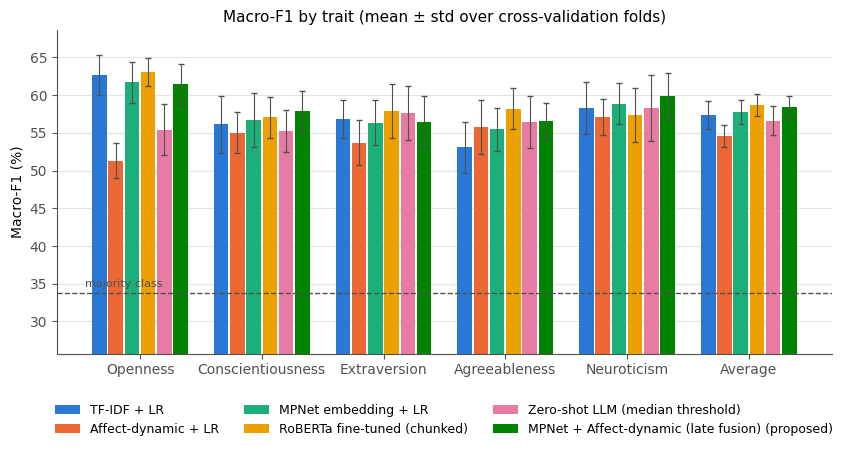

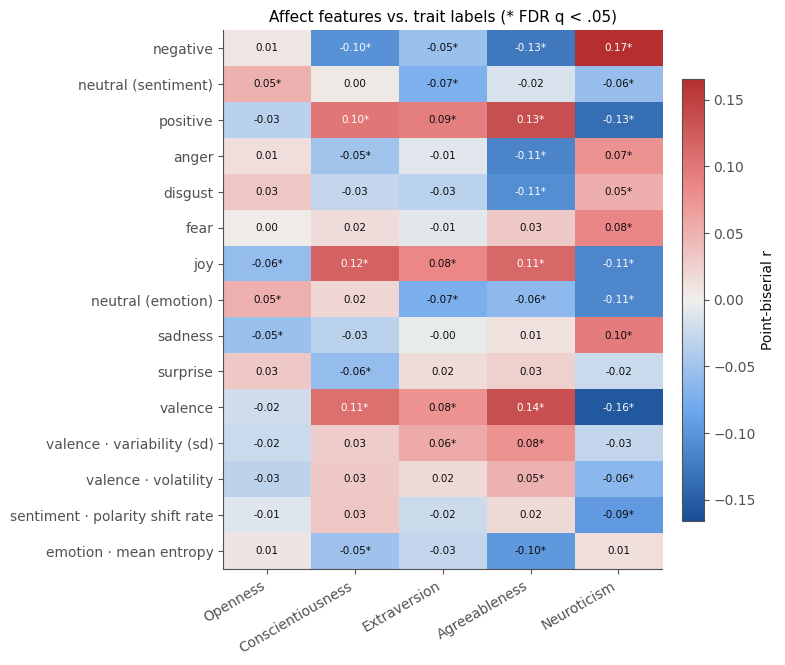

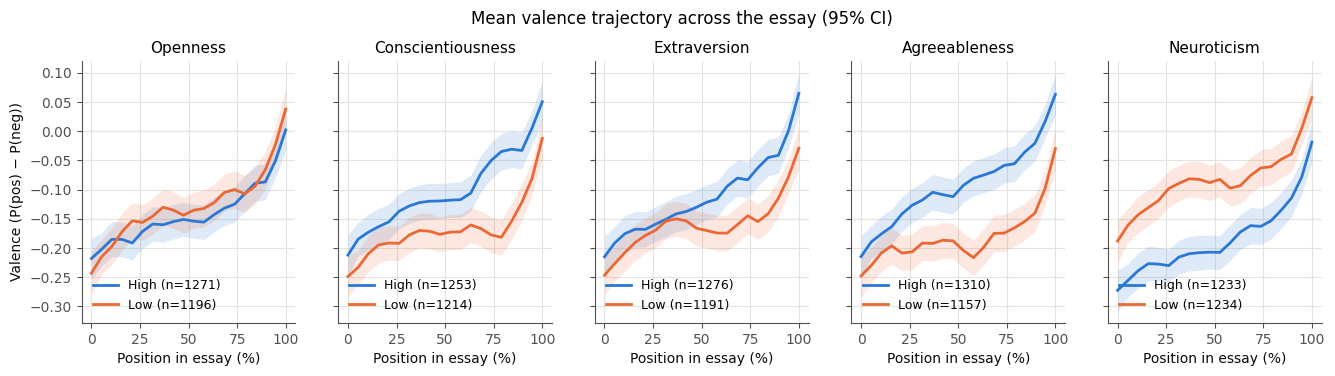

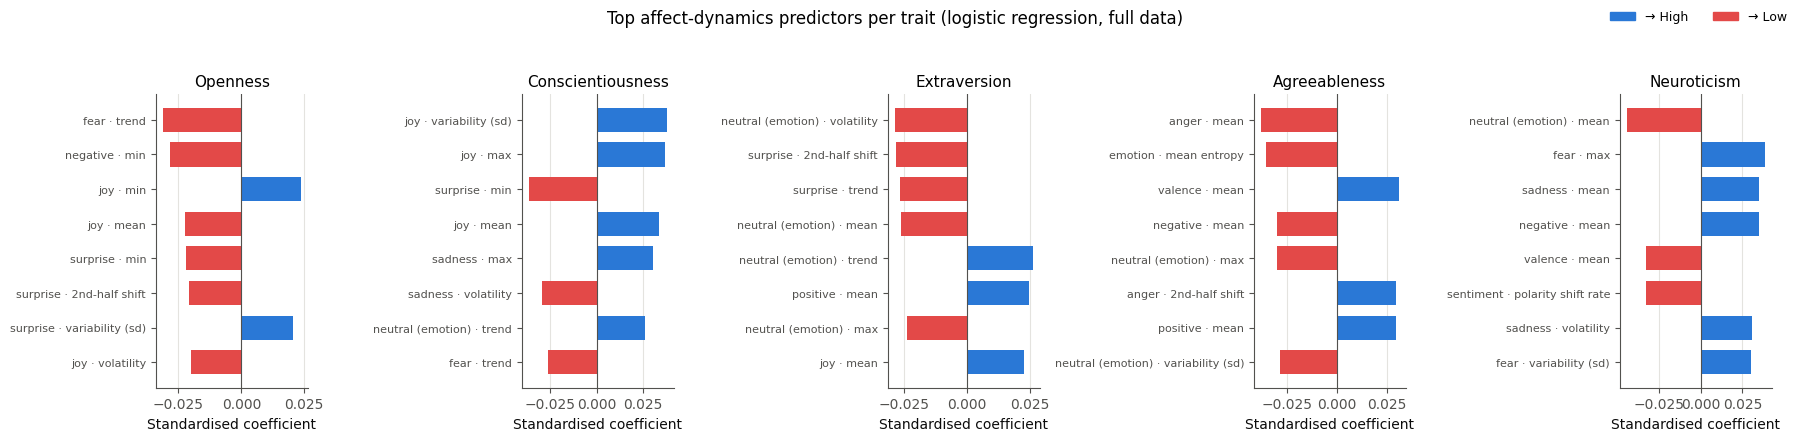

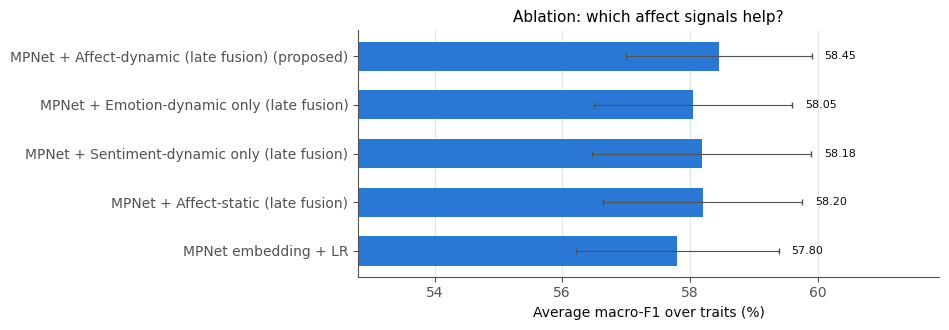

In [21]:
# ================================================================
# 11. Figures (300 dpi, ready for the paper)
# ================================================================
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#52514e",
    "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b52f2f"])
POS, NEG = "#2a78d6", "#e34948"


STAT_LABEL = {"mean": "mean", "std": "variability (sd)", "min": "min", "max": "max", "slope": "trend",
              "volatility": "volatility", "half_shift": "2nd-half shift", "shift_rate": "polarity shift rate",
              "entropy": "mean entropy"}


def pretty_feat(f, with_stat=True):
    base, _, stat = f.partition("__")
    base = {"sent": "sentiment", "emo": "emotion"}.get(base, base)
    base = {"sent_neutral": "neutral (sentiment)", "emo_neutral": "neutral (emotion)"}.get(base, base)
    base = base.replace("sent_", "").replace("emo_", "")
    return f"{base} · {STAT_LABEL.get(stat, stat)}" if with_stat else base


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)


# --- Figure 1: model comparison (macro-F1 per trait) ---
fig_models = [m for m in [M_TFIDF, M_AFF_D, M_EMB, M_FT, M_LLM_MED, M_PROP] if m in R.model.unique()]
x = np.arange(len(TRAITS) + 1)
width = 0.8 / len(fig_models)
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, m in enumerate(fig_models):
    sub = R[R.model == m]
    means = [sub[sub.trait == t].f1.mean() * 100 for t in TRAITS]
    sds = [sub[sub.trait == t].f1.std() * 100 for t in TRAITS]
    avg = sub.groupby(["repeat", "fold"]).f1.mean() * 100
    means.append(avg.mean()); sds.append(avg.std())
    ax.bar(x + (i - (len(fig_models) - 1) / 2) * width, means, width * 0.9, yerr=sds, capsize=2,
           color=CAT[i], label=m.replace(" [proposed]", " (proposed)"), error_kw={"elinewidth": 0.8, "ecolor": "#52514e"})
maj = R[R.model == M_MAJ].f1.mean() * 100
ax.axhline(maj, color="#52514e", ls="--", lw=1)
ax.text(-0.45, maj + 0.6, "majority class", color="#52514e", fontsize=8, ha="left", va="bottom")
ax.set_xticks(x, [TRAIT_NAMES[t] for t in TRAITS] + ["Average"])
ax.set_ylabel("Macro-F1 (%)")
lo_y = min(R[R.model.isin(fig_models)].groupby(["model", "trait"]).f1.mean().min() * 100, maj) - 8
ax.set_ylim(max(0, lo_y), None)
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.set_title("Macro-F1 by trait (mean ± std over cross-validation folds)")
savefig(fig, "fig1_model_comparison")

# --- Figure 2: affect–trait correlations (point-biserial r, BH-FDR) ---
corr_feats = [f"{s}__mean" for s in series_names] + ["valence__std", "valence__volatility", "sent__shift_rate", "emo__entropy"]
r_mat = np.zeros((len(corr_feats), len(TRAITS))); p_mat = np.zeros_like(r_mat)
for i, fname in enumerate(corr_feats):
    for k in range(len(TRAITS)):
        r_mat[i, k], p_mat[i, k] = stats.pearsonr(A_all[:, idx_of[fname]], Y[:, k])
keep = ~np.isnan(r_mat).any(1)                      # drop constant features (undefined r)
corr_feats, r_mat, p_mat = [f for f, k in zip(corr_feats, keep) if k], r_mat[keep], p_mat[keep]
q_mat = multipletests(p_mat.ravel(), method="fdr_bh")[1].reshape(p_mat.shape)
pretty = [pretty_feat(f, with_stat=not f.endswith("__mean")) for f in corr_feats]
pd.DataFrame(r_mat, index=pretty, columns=TRAITS).round(3).to_csv(TAB / "affect_trait_correlation_r.csv")
pd.DataFrame(q_mat, index=pretty, columns=TRAITS).round(4).to_csv(TAB / "affect_trait_correlation_q_fdr.csv")
vmax = np.abs(r_mat).max()
fig, ax = plt.subplots(figsize=(6.2, 7))
im = ax.imshow(r_mat, cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(TRAITS)), [TRAIT_NAMES[t] for t in TRAITS], rotation=30, ha="right")
ax.set_yticks(range(len(pretty)), pretty)
for i in range(len(corr_feats)):
    for k in range(len(TRAITS)):
        star = "*" if q_mat[i, k] < 0.05 else ""
        ax.text(k, i, f"{r_mat[i, k]:.2f}{star}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(r_mat[i, k]) > 0.6 * vmax else "#0b0b0b")
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("Point-biserial r")
ax.set_title("Affect features vs. trait labels (* FDR q < .05)")
savefig(fig, "fig2_affect_trait_correlations")

# --- Figure 3: valence trajectories, High vs. Low per trait ---
GRID = np.linspace(0, 1, 20)
v_idx = series_names.index("valence")
traj = np.vstack([np.interp(GRID, np.linspace(0, 1, len(s)), s[:, v_idx]) if len(s) > 1
                  else np.full(len(GRID), s[0, v_idx]) for s in series])
fig, axes = plt.subplots(1, len(TRAITS), figsize=(16, 3.4), sharey=True)
for k, (t, ax) in enumerate(zip(TRAITS, axes)):
    for val, lab, col in [(1, "High", CAT[0]), (0, "Low", CAT[1])]:
        g = traj[Y[:, k] == val]
        mu, se = g.mean(0), g.std(0, ddof=1) / np.sqrt(len(g))
        ax.plot(GRID * 100, mu, color=col, lw=2, label=f"{lab} (n={len(g)})")
        ax.fill_between(GRID * 100, mu - 1.96 * se, mu + 1.96 * se, color=col, alpha=0.15, lw=0)
    ax.set_title(TRAIT_NAMES[t]); ax.set_xlabel("Position in essay (%)")
    ax.legend(frameon=False, loc="lower left")
axes[0].set_ylabel("Valence (P(pos) − P(neg))")
fig.suptitle("Mean valence trajectory across the essay (95% CI)", y=1.03)
savefig(fig, "fig3_valence_trajectories")

# --- Figure 4: most influential affect-dynamics features per trait (standardised LR coefficients) ---
fig, axes = plt.subplots(1, len(TRAITS), figsize=(18, 4.2))
coef_rows = []
for k, (t, ax) in enumerate(zip(TRAITS, axes)):
    est = make_lr().fit(A_dynamic, Y[:, k])
    coef = est[-1].coef_[0]
    coef_rows += [{"trait": t, "feature": f, "coef": c} for f, c in zip(A_names, coef)]
    top = np.argsort(np.abs(coef))[-8:]
    ax.barh(range(len(top)), coef[top], color=[POS if c > 0 else NEG for c in coef[top]], height=0.7)
    ax.set_yticks(range(len(top)), [pretty_feat(A_names[i]) for i in top], fontsize=8)
    ax.axvline(0, color="#52514e", lw=0.8); ax.grid(axis="y", visible=False)
    ax.set_title(TRAIT_NAMES[t]); ax.set_xlabel("Standardised coefficient")
pd.DataFrame(coef_rows).to_csv(TAB / "affect_lr_coefficients.csv", index=False)
fig.legend(handles=[matplotlib.patches.Patch(color=POS, label="→ High"),
                    matplotlib.patches.Patch(color=NEG, label="→ Low")],
           loc="upper right", ncol=2, frameon=False)
fig.suptitle("Top affect-dynamics predictors per trait (logistic regression, full data)", y=1.04)
fig.tight_layout()
savefig(fig, "fig4_affect_coefficients")

# --- Figure 5: ablation (average macro-F1) ---
abl_names = [m for m in ABLATION_MODELS if m in R.model.unique()]
vals = [(R[R.model == m].groupby(["repeat", "fold"]).f1.mean() * 100) for m in abl_names]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(range(len(abl_names)), [v.mean() for v in vals], xerr=[v.std() for v in vals], color=CAT[0],
        height=0.6, capsize=2, error_kw={"elinewidth": 0.8, "ecolor": "#52514e"})
for i, v in enumerate(vals):
    ax.text(v.mean() + v.std() + 0.2, i, f"{v.mean():.2f}", va="center", fontsize=8, color="#0b0b0b")
ax.set_yticks(range(len(abl_names)), [m.replace(" [proposed]", " (proposed)") for m in abl_names])
lo_x = min(v.mean() for v in vals) - 5
ax.set_xlim(max(0, lo_x), max(v.mean() + v.std() for v in vals) + 2)
ax.set_xlabel("Average macro-F1 over traits (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Ablation: which affect signals help?")
savefig(fig, "fig5_ablation")

Cross-validated R² of each affect feature predicted from the MPNet embedding
statistic       mean    std    min    max  slope  volatility  half_shift
series                                                                  
sent_negative  0.503  0.050  0.131  0.267  0.075       0.035       0.052
sent_neutral   0.333  0.121  0.123  0.169  0.014       0.098       0.011
sent_positive  0.482  0.194  0.097  0.203  0.049       0.186       0.031
emo_anger      0.235  0.171  0.047  0.158  0.032       0.171       0.013
emo_disgust    0.211  0.154  0.031  0.142  0.030       0.159       0.015
emo_fear       0.280  0.212  0.001  0.159  0.036       0.202       0.014
emo_joy        0.362  0.242  0.002  0.170  0.021       0.266       0.014
emo_neutral    0.252  0.166  0.032  0.144  0.009       0.175       0.011
emo_sadness    0.285  0.169  0.027  0.133  0.053       0.165       0.049
emo_surprise   0.395  0.196  0.094  0.174  0.036       0.201       0.021
valence        0.508  0.086  0.238  0.196  0.06

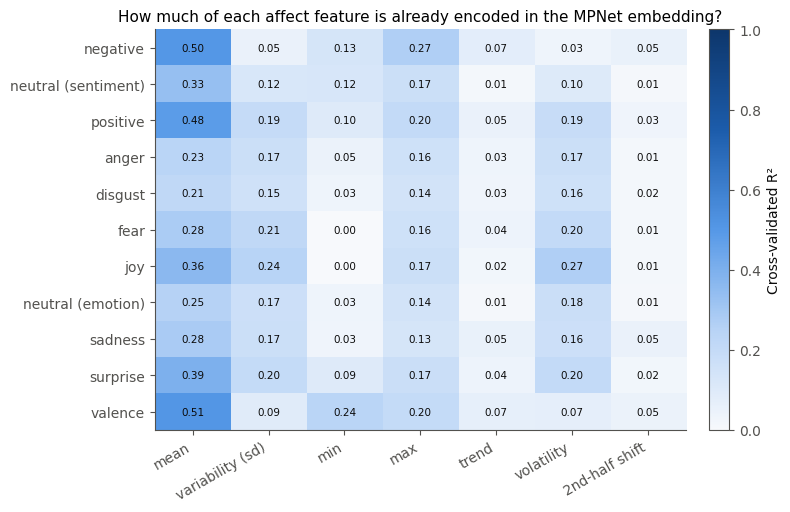


Correlation of out-of-fold probabilities between models:
             Trait  r(embedding, affect)  r(embedding, TF-IDF)  label agreement emb/affect (%)
         Openness                 0.259                 0.638                            59.1
Conscientiousness                 0.253                 0.487                            57.9
     Extraversion                 0.197                 0.484                            57.9
    Agreeableness                 0.309                 0.479                            62.8
      Neuroticism                 0.418                 0.525                            64.7

Valence trajectory: High vs. Low groups (Welch t-test, Benjamini-Hochberg FDR):
                  Feature             Trait  Mean High  Mean Low  Cohen's d     t       p  q (FDR)  Significant (q<.05)
          valence · mean          Openness    -0.1402   -0.1264     -0.043 -1.07 0.28295  0.35369                False
          valence · mean Conscientiousness    -0.1004   -

In [22]:
# ================================================================
# 11b. Why does fusion add so little? (1) redundancy of affect with the embeddings,
#      (2) agreement of model predictions, (3) statistical tests of the valence dynamics
# ================================================================
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

# (1) How much of every affect feature can be linearly recovered from the MPNet embedding?
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 5, 13), alpha_per_target=True))
A_hat = cross_val_predict(ridge, E, A_all, cv=KFold(5, shuffle=True, random_state=SEED))
sse = ((A_all - A_hat) ** 2).sum(0)
sst = ((A_all - A_all.mean(0)) ** 2).sum(0)
r2 = np.where(sst > 0, 1 - sse / np.where(sst > 0, sst, 1), np.nan)
red = pd.DataFrame({"feature": A_names, "R2_from_embedding": r2.round(4)})
red["series"] = [n.split("__")[0] for n in A_names]
red["statistic"] = [n.split("__")[1] for n in A_names]
red.to_csv(TAB / "redundancy_r2_affect_from_embedding.csv", index=False)
grid = red[red.series.isin(series_names)].pivot(index="series", columns="statistic", values="R2_from_embedding")
grid = grid.loc[series_names, STAT_NAMES]
print("Cross-validated R² of each affect feature predicted from the MPNet embedding")
print(grid.round(3).to_string())
print(f"\nMean R²: static (means) = {red[red.statistic == 'mean'].R2_from_embedding.mean():.3f} | "
      f"dynamic statistics (non-mean) = {red[red.statistic != 'mean'].R2_from_embedding.mean():.3f}")

fig, ax = plt.subplots(figsize=(7.5, 5.2))
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f7f9fc", "#b7d3f6", "#5598e7", "#1c5cab", "#0d366b"])
im = ax.imshow(grid.values.clip(min=0), cmap=SEQ, vmin=0, vmax=1, aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(STAT_NAMES)), [STAT_LABEL[s] for s in STAT_NAMES], rotation=30, ha="right")
ax.set_yticks(range(len(series_names)), [pretty_feat(s, with_stat=False) for s in series_names])
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if v > 0.55 else "#0b0b0b")
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("Cross-validated R²")
ax.set_title("How much of each affect feature is already encoded in the MPNet embedding?")
savefig(fig, "fig6_redundancy_r2")

# (2) Do the affect-only and embedding-only models make similar predictions?
agree = []
for k, t in enumerate(TRAITS):
    pe, pa, pt = OOF[M_EMB][0][:, k], OOF[M_AFF_D][0][:, k], OOF[M_TFIDF][0][:, k]
    agree.append({"Trait": TRAIT_NAMES[t],
                  "r(embedding, affect)": round(stats.pearsonr(pe, pa)[0], 3),
                  "r(embedding, TF-IDF)": round(stats.pearsonr(pe, pt)[0], 3),
                  "label agreement emb/affect (%)": round(100 * ((pe >= .5) == (pa >= .5)).mean(), 1)})
agree = pd.DataFrame(agree)
agree.to_csv(TAB / "prediction_agreement.csv", index=False)
print("\nCorrelation of out-of-fold probabilities between models:\n", agree.to_string(index=False))

# (3) Are the valence-trajectory differences between High and Low groups significant?
dyn_rows = []
for feat in ["valence__mean", "valence__slope", "valence__half_shift", "valence__volatility"]:
    x = A_all[:, idx_of[feat]]
    for k, t in enumerate(TRAITS):
        hi, lo = x[Y[:, k] == 1], x[Y[:, k] == 0]
        tstat, p = stats.ttest_ind(hi, lo, equal_var=False)
        d = (hi.mean() - lo.mean()) / np.sqrt((hi.var(ddof=1) + lo.var(ddof=1)) / 2)
        dyn_rows.append({"Feature": pretty_feat(feat), "Trait": TRAIT_NAMES[t], "Mean High": round(hi.mean(), 4),
                         "Mean Low": round(lo.mean(), 4), "Cohen's d": round(d, 3), "t": round(tstat, 2), "p": p})
dyn = pd.DataFrame(dyn_rows)
dyn["q (FDR)"] = multipletests(dyn.p, method="fdr_bh")[1]
dyn["Significant (q<.05)"] = dyn["q (FDR)"] < 0.05
dyn["p"] = dyn.p.round(5); dyn["q (FDR)"] = dyn["q (FDR)"].round(5)
dyn.to_csv(TAB / "valence_dynamics_tests.csv", index=False)
print("\nValence trajectory: High vs. Low groups (Welch t-test, Benjamini-Hochberg FDR):\n", dyn.to_string(index=False))

In [23]:
# ================================================================
# 12. Error analysis (proposed model, out-of-fold predictions of repeat 1)
# ================================================================
P_prop = OOF[M_PROP][0]
err = pd.DataFrame({"essay_id": np.arange(N), "n_words": df.n_words.values,
                    "text_excerpt": [t[:300] for t in texts]})
for k, t in enumerate(TRAITS):
    err[f"{t}_true"] = Y[:, k]
    err[f"{t}_prob"] = P_prop[:, k].round(4)
    err[f"{t}_correct"] = ((P_prop[:, k] >= 0.5).astype(int) == Y[:, k])
err["n_traits_wrong"] = (~err[[f"{t}_correct" for t in TRAITS]]).sum(1)
err.to_csv(OUT / "error_analysis_oof_predictions.csv", index=False)

print("Distribution of the number of traits misclassified per essay:")
print(err.n_traits_wrong.value_counts().sort_index().to_string())
q = pd.qcut(err.n_words, 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])
acc_len = pd.DataFrame({TRAIT_NAMES[t]: err.groupby(q, observed=True)[f"{t}_correct"].mean().round(3) for t in TRAITS})
acc_len.to_csv(TAB / "accuracy_by_essay_length.csv")
print("\nAccuracy by essay-length quartile:\n", acc_len)

for k, t in enumerate(TRAITS):
    wrong = err[~err[f"{t}_correct"]].copy()
    wrong["confidence"] = (wrong[f"{t}_prob"] - 0.5).abs()
    print(f"\n--- {TRAIT_NAMES[t]}: most confident errors ---")
    for _, row in wrong.nlargest(2, "confidence").iterrows():
        print(f"[true={'High' if row[f'{t}_true'] else 'Low'}, p(High)={row[f'{t}_prob']:.2f}] "
              f"{row.text_excerpt[:200]}...")

Distribution of the number of traits misclassified per essay:
n_traits_wrong
0    180
1    632
2    812
3    569
4    237
5     37

Accuracy by essay-length quartile:
              Openness  Conscientiousness  Extraversion  Agreeableness  \
n_words                                                                 
Q1 shortest     0.616              0.574         0.549          0.598   
Q2              0.597              0.582         0.585          0.582   
Q3              0.608              0.569         0.561          0.590   
Q4 longest      0.607              0.601         0.560          0.568   

             Neuroticism  
n_words                   
Q1 shortest        0.611  
Q2                 0.580  
Q3                 0.592  
Q4 longest         0.609  

--- Openness: most confident errors ---
[true=Low, p(High)=0.86] I feel kind of strange doing this assignment like this -- I don't think I've ever had such an informal assignment. I just got off the phone with this girl that I met

In [24]:
# ================================================================
# 13. Package everything for download
# ================================================================
shutil.make_archive("personality_affect_outputs", "zip", OUT)
print("All outputs saved to", OUT.resolve())
print("Download: personality_affect_outputs.zip")
for p in sorted(OUT.rglob("*")):
    if p.is_file() and "cache" not in p.parts:
        print("  ", p.relative_to(OUT))

All outputs saved to /kaggle/working/outputs
Download: personality_affect_outputs.zip
   affect_features.csv
   error_analysis_oof_predictions.csv
   figures/fig1_model_comparison.pdf
   figures/fig1_model_comparison.png
   figures/fig2_affect_trait_correlations.pdf
   figures/fig2_affect_trait_correlations.png
   figures/fig3_valence_trajectories.pdf
   figures/fig3_valence_trajectories.png
   figures/fig4_affect_coefficients.pdf
   figures/fig4_affect_coefficients.png
   figures/fig5_ablation.pdf
   figures/fig5_ablation.png
   figures/fig6_redundancy_r2.pdf
   figures/fig6_redundancy_r2.png
   fold_results.csv
   run_config.json
   tables/ablation_f1.csv
   tables/ablation_f1.tex
   tables/accuracy_by_essay_length.csv
   tables/affect_lr_coefficients.csv
   tables/affect_trait_correlation_q_fdr.csv
   tables/affect_trait_correlation_r.csv
   tables/dataset_label_balance.csv
   tables/finetune_training_log.csv
   tables/late_fusion_meta_weights.csv
   tables/main_acc.csv
   tables/ma

## Notes for the paper

**Reporting.** Use `tables/main_f1.csv` (or the `.tex` version) as the main results table, `ablation_f1` for the ablation, `significance_proposed_vs_others.csv` for the significance tests, and figures 1–5. Report the honest outcome: if the affect signals do not significantly improve over the embedding-only model, that is a valid and publishable negative finding.

**Ethics and limitations (to include in the paper).**
- The Essays corpus comes from US psychology undergraduates (1997–2004). Results may not transfer to other populations, languages or genres such as social media.
- Labels are binary (median split) self-reports, which discard information and carry measurement error.
- The sentiment model was trained on tweets and the emotion model on mixed web text, so there is a domain shift on essays.
- Automatic personality inference can enable profiling without consent. The models are research artefacts and are not intended for decisions about individuals (hiring, credit, clinical use).
- The zero-shot LLM may have seen the essays during pre-training (possible data contamination).